In [ ]:
import sys
import config as C
import numpy as np
import pandas as pd
from pathlib import Path
from src import save_plot
from src import PATHWAY_COLOUR
import matplotlib.pyplot as plt
from xgboost import XGBClassifier
from sklearn.metrics import average_precision_score, confusion_matrix

sys.path.insert(0, str(Path.cwd().parent))

CLASSES = ["sensitivity", "neutral", "resistance"]
CLASS_INDEX = {name: position for position, name in enumerate(CLASSES)}
CLASS_COLOUR = {"sensitivity": "#009ADE", "neutral": "#9aa0a6", "resistance": "#FF1F5B"}
DRAWS, SEEDS = 10, 3
REPEATS = DRAWS * SEEDS
INTEGER = {"max_depth", "n_estimators", "min_child_weight"}

# Held-out validation

Three leave-one-out designs:

- **one gene held out**, over all 30 genes
- **one cell line held out**, over 2 cell lines
- **one compound held out**, over 3 drugs


In [2]:
X = pd.read_csv(C.DATA / "model_matrix_X.csv.gz", index_col="row_id")
y = pd.read_csv(C.DATA / "model_matrix_y.csv.gz", index_col="row_id")
dictionary = pd.read_csv(C.DATA / "model_matrix_features.csv", index_col="feature")
assert X.index.equals(y.index), "X and y are not aligned"

search = pd.read_csv(C.DATA / "model_hyperparameter_search.csv").sort_values(
    "resistance", ascending=False
)
space = [c for c in search.columns
         if c not in {"sensitivity", "neutral", "resistance", "macro", "is_default"}]
best = search.iloc[0]
PARAMETERS = {
    name: int(best[name]) if name in INTEGER else float(best[name]) for name in space
}
print(f"{len(y):,} rows, {y.gene.nunique()} genes, {y.cell_line.nunique()} cell lines, "
      f"{y.compound.nunique()} compounds")
pd.Series(PARAMETERS, name="value").rename_axis("hyperparameter").to_frame()

83,352 rows, 30 genes, 2 cell lines, 3 compounds


,value
hyperparameter,
max_depth,8.00
learning_rate,0.02
n_estimators,400.00
min_child_weight,3.00
subsample,0.80
colsample_bytree,0.60
reg_lambda,0.50
gamma,1.00


In [3]:
GROUPS = {name: list(dictionary.index[dictionary.group == name])
          for name in dictionary.group.unique()}
ANNOTATION = GROUPS["annotation"]
PROTVAR = GROUPS["protvar"]
CONTEXT = GROUPS["cellular"] + GROUPS["drug"]
FEATURE_SETS = {
    "Full model": ANNOTATION + PROTVAR + CONTEXT,
    "Cellular": CONTEXT,
    "Annotation": ANNOTATION,
    "Perturbation": ANNOTATION + PROTVAR,
}
pd.Series({name: len(columns) for name, columns in FEATURE_SETS.items()},
          name="features").to_frame()

,features
Full model,83
Cellular,7
Annotation,74
Perturbation,76


## Downsampling and fitting


In [4]:
def downsample(frame, draw):
    called = frame[frame.call != "neutral"]
    neutral = frame[frame.call == "neutral"]
    target = int(frame.call.value_counts().iloc[1])
    fraction = min(1.0, target / len(neutral))
    generator = np.random.default_rng(draw)
    chosen = []
    for positions in neutral.groupby(["gene", "cell_line"]).indices.values():
        wanted = min(len(positions), max(1, int(round(len(positions) * fraction))))
        chosen.append(generator.choice(positions, size=wanted, replace=False))
    return pd.concat([called, neutral.iloc[np.concatenate(chosen)]])

In [5]:
def fit_model(features, labels, seed):
    return XGBClassifier(
        objective="multi:softprob", num_class=len(CLASSES), tree_method="hist",
        n_jobs=4, random_state=seed, verbosity=0, **PARAMETERS,
    ).fit(features, labels)


def auprc_by_class(labels, probability):
    scores = {}
    for name, index in CLASS_INDEX.items():
        truth = (labels == index).astype(int)
        scores[name] = (
            average_precision_score(truth, probability[:, index])
            if 0 < truth.sum() < len(truth) else np.nan
        )
    return scores

## Leave one out


In [6]:
table = y.join(X)


def leave_one_out(axis, columns, draws=DRAWS, seeds=SEEDS):
    rows, matrix = [], np.zeros((len(CLASSES), len(CLASSES)))
    for draw in range(draws):
        block = downsample(table, draw)
        features = block[columns].astype(float).to_numpy()
        labels = block.call.map(CLASS_INDEX).to_numpy()
        levels = block[axis].to_numpy()
        for seed in range(seeds):
            for level in np.unique(levels):
                test = levels == level
                # a level needs two classes to be scored, and training needs all three
                if len(set(labels[test])) < 2 or len(set(labels[~test])) < len(CLASSES):
                    continue
                model = fit_model(features[~test], labels[~test], seed)
                probability = model.predict_proba(features[test])
                matrix += confusion_matrix(labels[test], probability.argmax(axis=1),
                                           labels=range(len(CLASSES)))
                rows.append({
                    "axis": axis, "level": level, "draw": draw, "seed": seed,
                    "n": int(test.sum()),
                    **auprc_by_class(labels[test], probability),
                    **{f"{name} chance": float((labels[test] == index).mean())
                       for name, index in CLASS_INDEX.items()},
                })
    return pd.DataFrame(rows), matrix

In [7]:
AXES = ["gene", "cell_line", "compound"]
evaluated = {axis: leave_one_out(axis, FEATURE_SETS["Full model"]) for axis in AXES}
held_out = pd.concat([frame for frame, _ in evaluated.values()], ignore_index=True)
designs = {f"{axis} held out": matrix for axis, (_, matrix) in evaluated.items()}
print(f"{len(held_out):,} fits over {held_out.level.nunique()} held-out levels")
held_out.groupby("axis")[CLASSES].mean()

1,050 fits over 35 held-out levels


,sensitivity,neutral,resistance
axis,,,
cell_line,0.157580,0.548043,0.513772
compound,0.408283,0.578947,0.674402
gene,0.316466,0.724467,0.534631


In [8]:
reference = pd.read_csv(C.DATA / "model_auprc_summary.csv", index_col=0)
comparison = pd.concat([
    reference.loc[["Full model"], CLASSES].rename(index={"Full model": "variant held out"}),
    held_out.groupby("axis")[CLASSES].mean().rename(
        index={"gene": "gene held out", "cell_line": "cell line held out",
               "compound": "compound held out"}
    ),
])
comparison

,sensitivity,neutral,resistance
variant held out,0.743641,0.723885,0.803383
cell line held out,0.157580,0.548043,0.513772
compound held out,0.408283,0.578947,0.674402
gene held out,0.316466,0.724467,0.534631


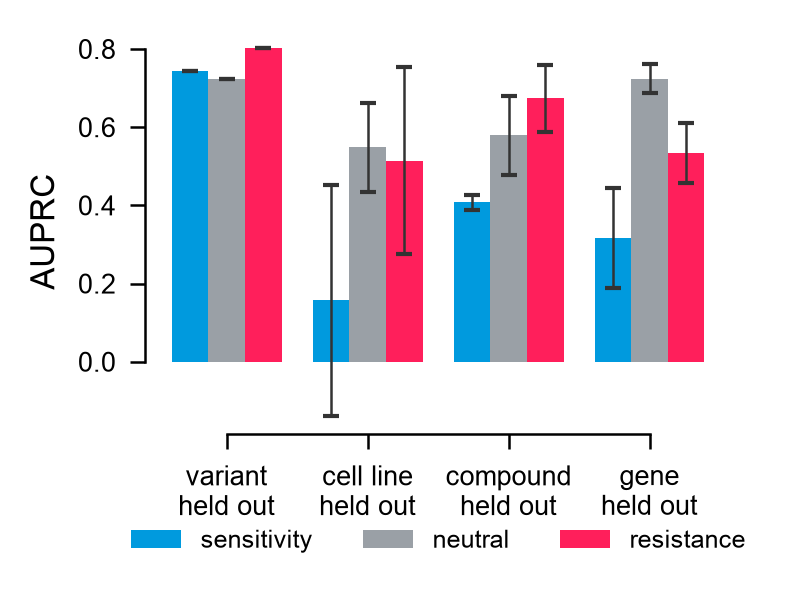

In [21]:
fig, ax = plt.subplots(figsize=(2.5, 2))

width = 0.26
positions = np.arange(len(comparison))
spread = held_out.groupby("axis")[CLASSES].std()

for offset, name in zip([-width, 0, width], CLASSES):
    errors = [0.0] + [spread.loc[axis, name] for axis in ["gene", "cell_line", "compound"]]
    
    ax.bar(positions + offset, comparison[name], width=width, yerr=errors, capsize=2,
           color=CLASS_COLOUR[name], label=name, linewidth=0,
           error_kw=dict(lw=0.6, ecolor="#333333"))

ax.set_xticks(positions)
ax.set_xticklabels([n.replace(" held out", "\nheld out") for n in comparison.index],
                   fontsize=6)
ax.set_ylabel("AUPRC")

ax.legend(frameon=False, fontsize=6, loc="upper center", bbox_to_anchor=(0.5, -0.18),
          ncol=3)
fig.tight_layout(pad=0.3, rect=(0, 0.06, 1, 1))
ax.tick_params(labelsize=6.5)

save_plot(fig, "heldout_designs")
plt.show()

## Phenotypic class prediction


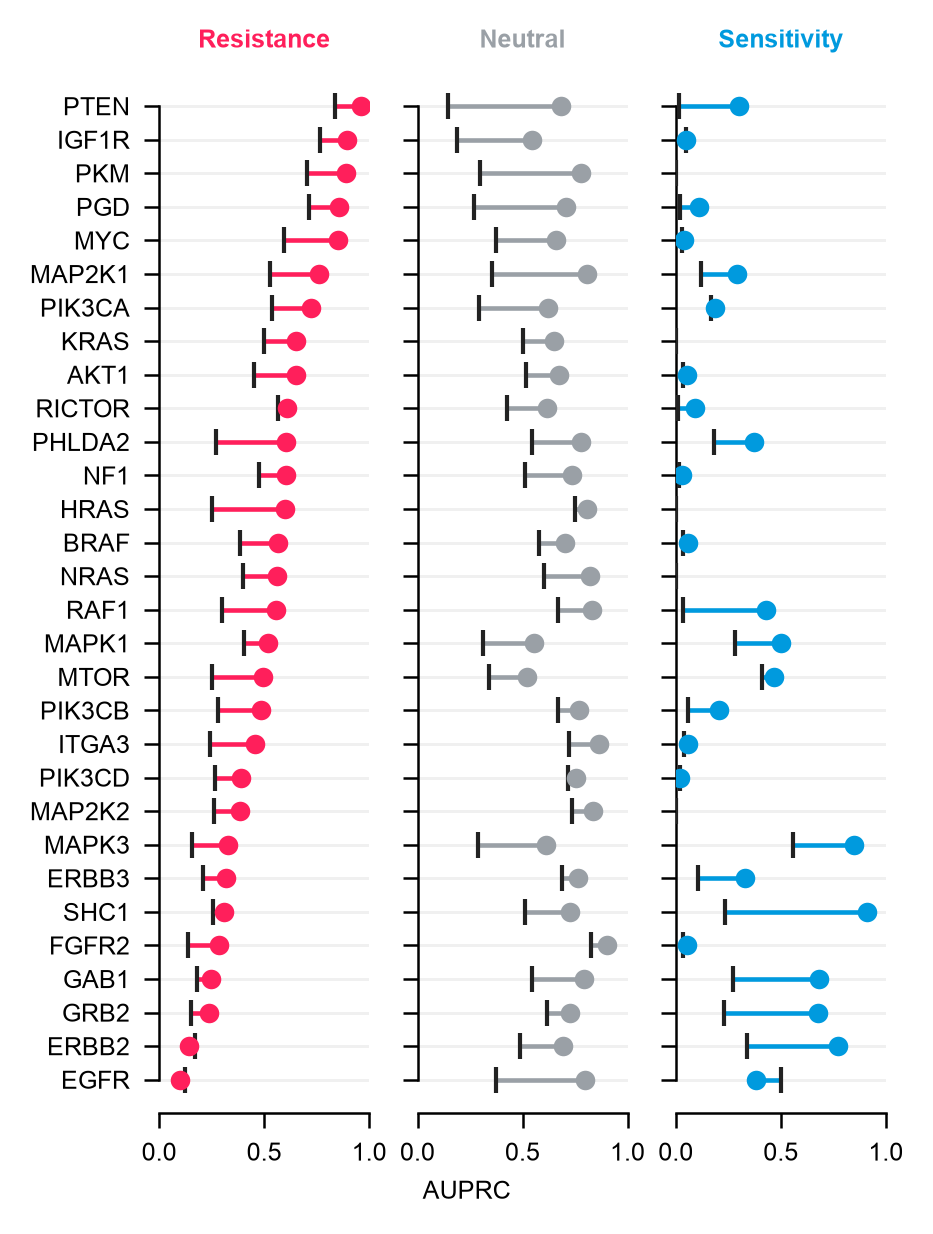

In [35]:
def level_table(axis):
    block = held_out[held_out.axis == axis]
    columns = CLASSES + [f"{name} chance" for name in CLASSES]
    return block.groupby("level")[columns].mean().sort_values("resistance")


def lollipops(frame, name, width, height, label):
    order = ["resistance", "neutral", "sensitivity"]
    
    fig, axes = plt.subplots(1, 3, figsize=(width, height), sharey=True)
    
    positions = np.arange(len(frame))
    
    for ax, class_name in zip(axes, order):
        ax.hlines(positions, 0, 1, color="#f0f0f0", lw=0.7, zorder=1)
        ax.hlines(positions, frame[f"{class_name} chance"], frame[class_name],
                  color=CLASS_COLOUR[class_name], lw=1.1, zorder=2)
        ax.scatter(frame[class_name], positions, s=22, linewidths=0,
                   color=CLASS_COLOUR[class_name], zorder=4)
        ax.scatter(frame[f"{class_name} chance"], positions, marker="|", s=38,
                   color="#222222", linewidths=1.0, zorder=3)
        ax.set_title(class_name.capitalize(), fontsize=6,
                     color=CLASS_COLOUR[class_name], fontweight="bold")
        ax.set_xlim(0, 1)
        ax.set_xticks([0, 0.5, 1.0])
        ax.tick_params(labelsize=6)
        ax.spines[["top", "right"]].set_visible(False)
    
    axes[0].set_yticks(positions)
    axes[0].set_yticklabels(frame.index, fontsize=6)
    axes[0].set_ylim(-1, len(frame))
    
    fig.supxlabel(label, fontsize=6)
    fig.tight_layout(pad=0.4)
    
    save_plot(fig, name)
    plt.show()

lollipops(level_table("gene"), "heldout_auprc_by_gene", 3, 4, "AUPRC")

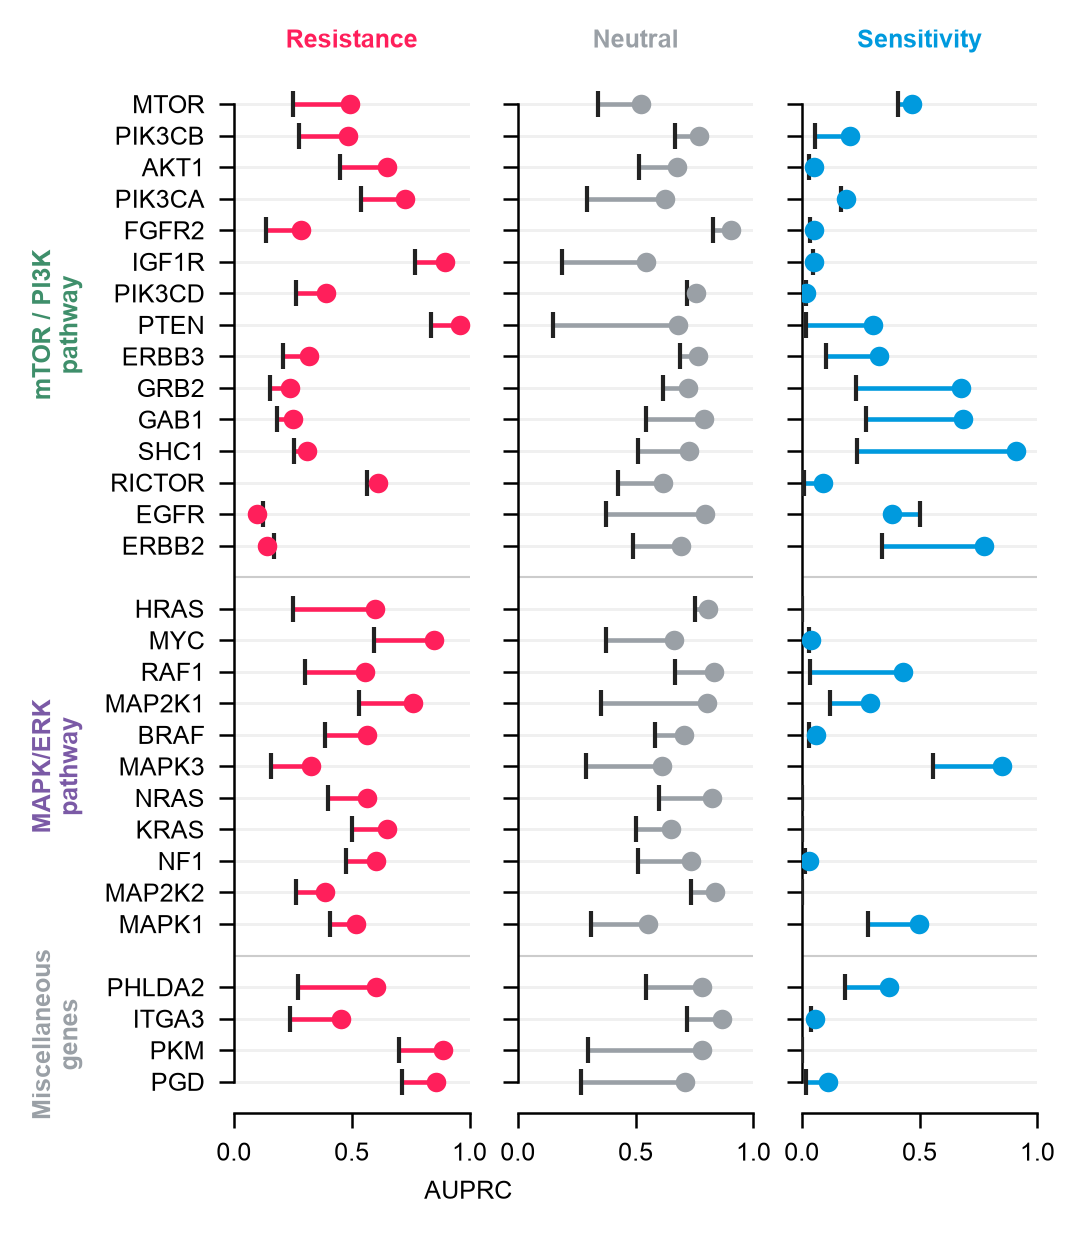

In [53]:
PATHWAY_ORDER = list(C.GENE_GROUPS)[::-1]
PANEL_ORDER = ["resistance", "neutral", "sensitivity"]

grouped = (
    level_table("gene")
    .dropna(subset=["resistance"])
    .assign(
        pathway=lambda d: pd.Categorical(
            d.index.map(C.GENE_PATHWAY), categories=PATHWAY_ORDER, ordered=True
        ),
        gain=lambda d: d.resistance - d["resistance chance"],
    )
    .sort_values(["pathway", "gain"], ascending=[True, True])
)

# one blank row between pathways, so the groups read as blocks
gene_row, cursor, pathway_centres, pathway_edges = {}, 0, [], []
for pathway, block in grouped.groupby("pathway", observed=True, sort=False):
    start = cursor
    for gene in block.index:
        gene_row[gene] = cursor
        cursor += 1
    pathway_centres.append((start + cursor - 1) / 2)
    pathway_edges.append(cursor)
    cursor += 1
gene_rows = np.array([gene_row[gene] for gene in grouped.index])

fig, axes = plt.subplots(1, 3, figsize=(4, 4), sharey=True)
for ax, class_name in zip(axes, PANEL_ORDER):
    ax.hlines(gene_rows, 0, 1, color="#f0f0f0", lw=0.7, zorder=1)
    ax.hlines(gene_rows, grouped[f"{class_name} chance"], grouped[class_name],
              color=CLASS_COLOUR[class_name], lw=1.1, zorder=2)
    ax.scatter(grouped[class_name], gene_rows, s=22, linewidths=0,
               color=CLASS_COLOUR[class_name], zorder=4)
    ax.scatter(grouped[f"{class_name} chance"], gene_rows, marker="|", s=38,
               color="#222222", linewidths=1.0, zorder=3)
    for edge in pathway_edges[:-1]:
        ax.axhline(edge, color="#cccccc", lw=0.5, zorder=0)
    ax.set_title(class_name.capitalize(), fontsize=6,
                 color=CLASS_COLOUR[class_name], fontweight="bold")
    ax.set_xlim(0, 1)
    ax.set_xticks([0, 0.5, 1.0])
    ax.tick_params(labelsize=6)
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_yticks(gene_rows, grouped.index, fontsize=6)
for centre, pathway in zip(pathway_centres, PATHWAY_ORDER):
    axes[0].text(-0.75, centre, pathway, fontsize=6, ha="center", va="center",
                 color=PATHWAY_COLOUR[pathway], fontweight="bold", rotation=90,
                 transform=axes[0].get_yaxis_transform())
axes[0].set_ylim(-1, cursor - 1)
fig.supxlabel("AUPRC", fontsize=6)
fig.tight_layout(pad=0.4, rect=(0.10, 0, 1, 1))
save_plot(fig, "heldout_auprc_by_gene_pathway")
plt.show()

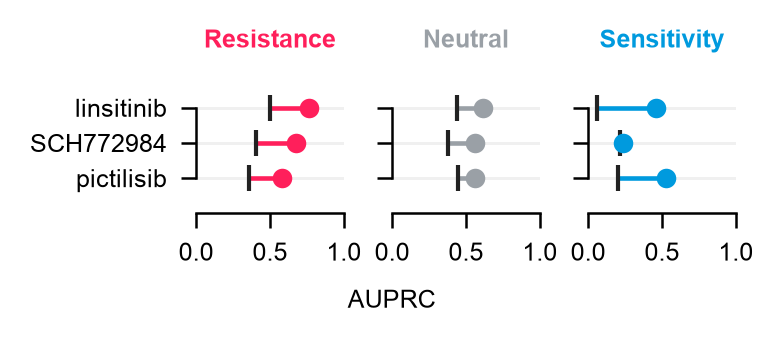

In [36]:
lollipops(level_table("compound"), "heldout_auprc_by_drug", 2.5, 1, "AUPRC")

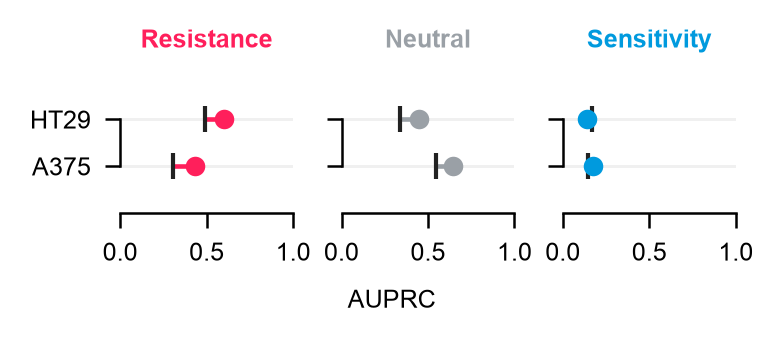

In [37]:
lollipops(level_table("cell_line"), "heldout_auprc_by_cell_line", 2.5, 1, "AUPRC")

## Confusion matrices


In [14]:
by_set = {
    name: leave_one_out("gene", columns, draws=3, seeds=1)[1]
    for name, columns in FEATURE_SETS.items()
}

In [39]:
def confusion_panel(matrices, name, width, height):
    fig, axes = plt.subplots(1, len(matrices), figsize=(width, height))
    for ax, (title, matrix) in zip(np.atleast_1d(axes), matrices.items()):
        shares = matrix / matrix.sum(axis=1, keepdims=True)
        ax.imshow(shares, cmap="Blues", vmin=0, vmax=1)
        for row in range(len(CLASSES)):
            for column in range(len(CLASSES)):
                ax.text(column, row, f"{shares[row, column]:.2f}", ha="center",
                        va="center", fontsize=6,
                        color="white" if shares[row, column] > 0.5 else "#222222")
        ax.set_xticks(range(len(CLASSES)))
        ax.set_xticklabels(CLASSES, fontsize=5.5, rotation=45, ha="right")
        ax.set_yticks(range(len(CLASSES)))
        ax.set_yticklabels(CLASSES if ax is np.atleast_1d(axes)[0] else [], fontsize=5.5)
        ax.set_title(f"{title}\n(accuracy {np.trace(matrix) / matrix.sum():.2f})",
                     fontsize=7)
        ax.set_xlabel("predicted", fontsize=6)
    np.atleast_1d(axes)[0].set_ylabel("true", fontsize=6)
    fig.tight_layout(pad=0.3)
    save_plot(fig, name)
    plt.show()

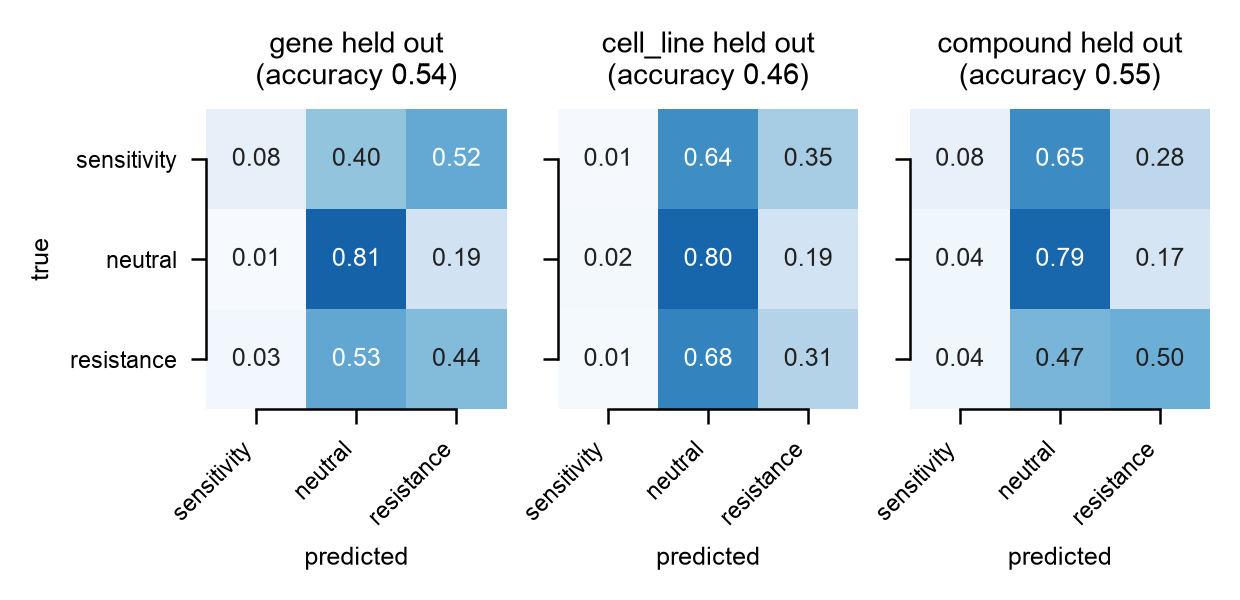

In [40]:
confusion_panel(designs, "heldout_confusion_by_design", 4, 2)

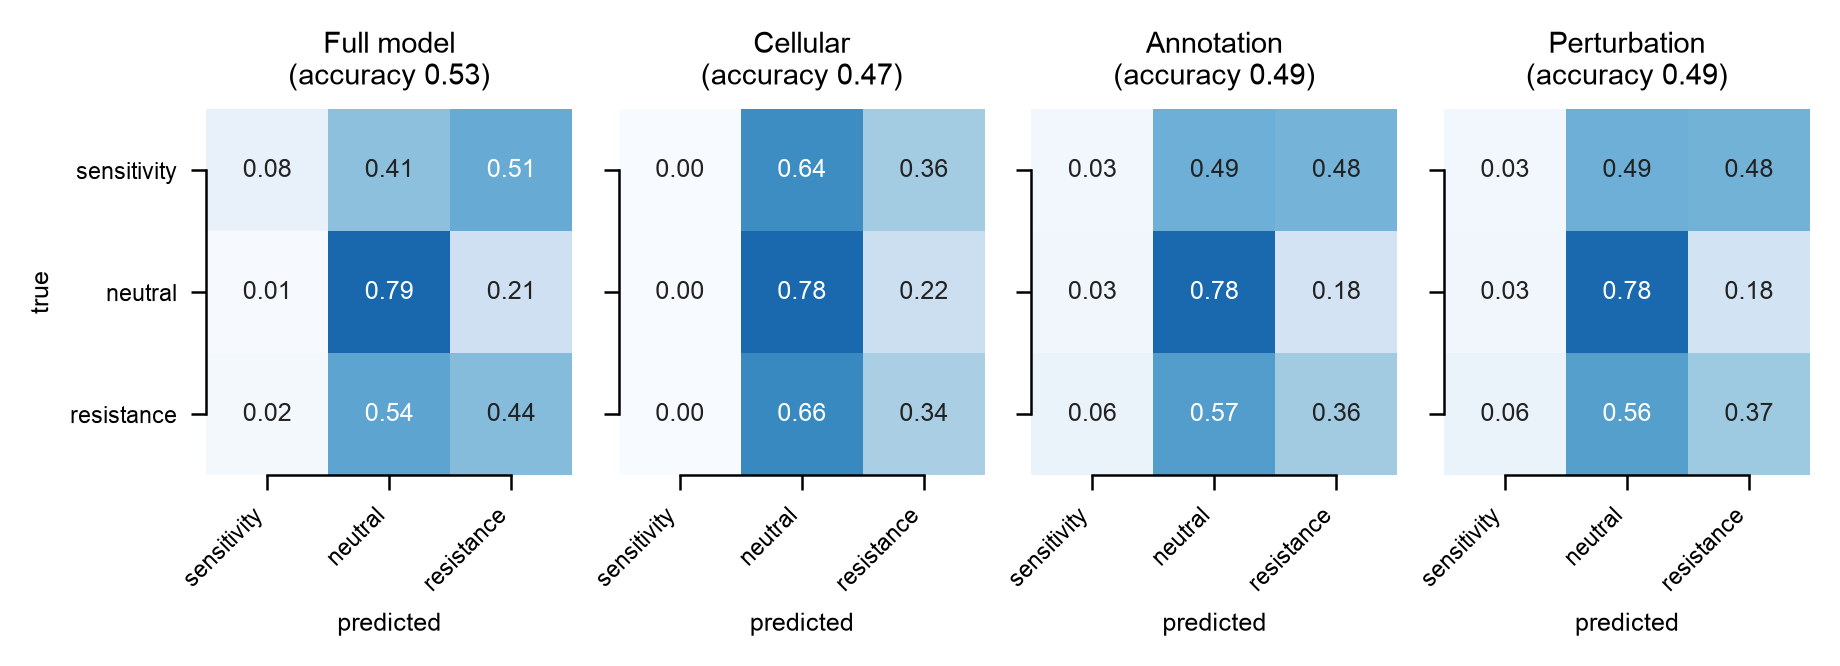

In [41]:
confusion_panel(by_set, "heldout_confusion_by_feature_set", 6, 2)